# 1. First run: a stormy week in 2020

In this tutorial you run PyPSA-GB for one week of 2020 on its smallest network, open the result, and check it against
what actually happened. The week is 10 to 16 February 2020: Storm Dennis crossed Great Britain on 15 and 16 February,
and wind was strong for most of the week. The run takes about five minutes on a laptop.

You will see:

- how a scenario is defined and run;
- what a solved network contains;
- how GB demand was met, hour by hour;
- how close the model comes to the real week;
- where the network limited power flows, and what that did to prices.

The same week runs through tutorials 2 to 5: on larger networks (2), in 2030 and 2040 (3 and 4), and through the
two-stage market (5).

## The scenario

A scenario is a short block of settings; everything it does not set comes from the defaults in `config/defaults/`.
This one is in `config/studies/tutorials/scenarios.yaml`:

```yaml
Tutorial_2020_reduced:
  description: 'Tutorials: 10-16 February 2020 on the Reduced network (32 buses)'
  targets: {source: historical, edition: null, pathway: null}   # numbers from outturn, not a projection
  method: historical                    # fleet from DUKES (thermal) and REPD (renewables and storage)
  modelled_year: 2020                   # the system modelled
  renewables_year: 2020                 # weather year for wind, solar and hydro
  demand_year: 2020                     # year of the demand profile (ESPENI)
  network_model: Reduced                # the 32-bus GB network
  solve_period:
    enabled: true
    start: 2020-02-10 00:00
    end: 2020-02-16 23:00
```

The network is solved as one linear optimal power flow over the 168 hours: least-cost dispatch of every generator,
storage unit and interconnector, subject to each line's limit ([single solve](../model/dispatch/single_solve.md)).

## Run it

1. Make sure `config/config.yaml` loads the tutorial scenarios:

   ```yaml
   studies:
     - tutorials
   ```

2. From the repository root, in the `pypsa-gb` environment:

   ```bash
   snakemake -j 4 --config scenario=Tutorial_2020_reduced
   ```

   Snakemake builds the network step by step (demand, renewables, thermal plant, storage, interconnectors) and
   solves it. The first run of a weather year also fetches its weather data ([installation](../getting_started/installation.md)).

3. The solved network is `resources/network/Tutorial_2020_reduced_solved.nc`, beside a short solver summary
   (`_optimization_summary.txt`), hourly tables in `resources/results/` and an interactive map and dashboard in
   `resources/analysis/` ([results](../getting_started/results.md)).

The cell below sets up the notebook: it moves to the repository root and defines a few helpers used throughout (which
technology each carrier belongs to, GB demand, net imports). Read it once; the rest of the notebook uses it.

In [1]:
from pathlib import Path
import logging
import os
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import pypsa

logging.getLogger("pypsa").setLevel(logging.ERROR)  # keep the notebook output short
warnings.filterwarnings("ignore", message=".*GDAL.*")
warnings.filterwarnings("ignore", message=".*gdalvrt.*")

# Work from the repository root, wherever Jupyter was started.
ROOT = Path.cwd()
while not (ROOT / "Snakefile").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)

# Technology groups for charts: each PyPSA-GB carrier belongs to one group.
GROUPS = {
    "Nuclear": ["nuclear"],
    "Coal": ["coal"],
    "Gas": ["CCGT", "OCGT", "gas_engine", "CHP", "CCS Gas"],
    "Oil": ["oil"],
    "Bioenergy": ["biomass", "CCS Biomass", "biogas", "landfill_gas", "sewage_gas", "waste_to_energy",
                  "advanced_biofuel", "geothermal"],
    "Hydro": ["large_hydro", "small_hydro"],
    "Marine": ["marine", "tidal_stream", "shoreline_wave", "tidal_lagoon"],
    "Onshore wind": ["wind_onshore", "embedded_wind"],
    "Offshore wind": ["wind_offshore", "floating_wind"],
    "Solar": ["solar_pv", "embedded_solar"],
}
GROUP_OF = {carrier: group for group, carriers in GROUPS.items() for carrier in carriers}
COLOURS = {
    "Nuclear": "#6250d6", "Coal": "#4b4b4b", "Gas": "#eb6834", "Oil": "#9b6a4f", "Bioenergy": "#008300",
    "Hydro": "#5fa8d3", "Marine": "#1f9e9e", "Onshore wind": "#1baf7a", "Offshore wind": "#2a78d6",
    "Solar": "#eda100", "Hydrogen": "#e34948", "Storage": "#e87ba4", "Imports": "#9aa5a0",
}
# Consumer flexibility (EVs, heat, demand response) is built from storage units but counts as demand.
CONSUMER_FLEX = {"EV_smart_charging", "V2G_fleet", "HP_flexibility", "DH_flexibility", "SH_flexibility",
                 "IC_DSR", "residential_DSR", "DACCS"}

plt.rcParams.update({"figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e9e7", "legend.frameon": False, "font.size": 10})


def load(path):
    """Open a solved network, or say how to make it."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{path} does not exist yet: run the scenario first (see 'Run it' above).")
    return pypsa.Network(path)


def series(n, component, attribute, names):
    """A time series for each named component; a component without one takes its static value (or zero)."""
    table = getattr(n, f"{component}_t")[attribute]
    static = getattr(n, component).get(attribute, pd.Series(0.0, index=getattr(n, component).index))
    out = table.reindex(columns=names)
    for name in out.columns[out.isna().all()]:
        out[name] = float(static.get(name, 0.0)) if attribute in ("p_set", "p_max_pu") else 0.0
    return out.fillna(0.0)


def link_output(n, names):
    """Power each link delivers at its bus1 end (MW): p0 times efficiency, so it works whether or not p1 was saved."""
    return series(n, "links", "p0", names) * n.links.efficiency.reindex(names).values


def gb_buses(n):
    """GB electricity buses (the hydrogen bus is left out)."""
    return n.buses.index[(n.buses.country == "GB") & (n.buses.carrier == "AC")]


def generation_by_group(n):
    """GB generation by technology group (MW per snapshot); hydrogen turbines are their own group."""
    gens = n.generators[n.generators.bus.isin(gb_buses(n)) & n.generators.carrier.isin(GROUP_OF)]
    out = series(n, "generators", "p", gens.index).T.groupby(gens.carrier.map(GROUP_OF)).sum().T
    turbines = n.links.index[n.links.carrier == "H2_turbine"]
    if len(turbines):
        out["Hydrogen"] = link_output(n, turbines).sum(axis=1)  # output at the electricity end
    return out[[g for g in COLOURS if g in out and out[g].abs().sum() > 0]]


def interconnectors(n):
    cc = n.links.get("counterparty_country", pd.Series("", index=n.links.index)).fillna("").astype(str)
    return n.links[(n.links.carrier == "DC") & ~cc.isin(["", "nan", "None"])]


def net_imports(n):
    """Power the interconnectors deliver into GB (MW; negative = export)."""
    ic = interconnectors(n)
    gb = set(gb_buses(n))
    flows = {}
    for name, link in ic.iterrows():
        # p0 and p1 are withdrawals at bus0 and bus1; the GB end receives minus its withdrawal.
        # Power into GB: at bus0 it is minus the flow out of bus0; at bus1 it is the link's output there.
        flows[name] = (-series(n, "links", "p0", [name])[name] if link.bus0 in gb
                       else link_output(n, [name])[name])
    return pd.DataFrame(flows, index=n.snapshots).sum(axis=1)


def grid_storage(n):
    """Net output of grid storage (MW; positive = discharging). Consumer flexibility is left out."""
    units = n.storage_units.index[~n.storage_units.carrier.isin(CONSUMER_FLEX)]
    return series(n, "storage_units", "p", units).sum(axis=1)


def gb_demand(n):
    """GB electricity demand (MW): loads, the net draw of consumer flexibility, and electrolysis."""
    loads = n.loads.index[n.loads.bus.isin(gb_buses(n))]
    demand = series(n, "loads", "p_set", loads).sum(axis=1)
    flex = n.storage_units.index[n.storage_units.carrier.isin(CONSUMER_FLEX)]
    if len(flex):
        demand = demand - series(n, "storage_units", "p", flex).sum(axis=1)
    electrolysers = n.links.index[n.links.carrier == "electrolysis"]
    if len(electrolysers):
        demand = demand + series(n, "links", "p0", electrolysers).sum(axis=1)
    return demand


def day_axis(ax):
    """Label a time axis by day: Mon 10 Feb."""
    import matplotlib.dates as mdates
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))


def stack_plot(ax, supply, demand=None, title=None):
    """Stacked supply (GW) by group, positive above zero and negative (charging, exports) below."""
    gw = supply / 1e3
    pos, neg = gw.clip(lower=0), gw.clip(upper=0)
    ax.stackplot(gw.index, pos.T.values, colors=[COLOURS[c] for c in gw.columns], labels=gw.columns, lw=0)
    ax.stackplot(gw.index, neg.T.values, colors=[COLOURS[c] for c in gw.columns], lw=0)
    if demand is not None:
        ax.plot(demand.index, demand / 1e3, color="black", lw=1.4, label="Demand")
    ax.axhline(0, color="#555", lw=0.6)
    ax.set_ylabel("GW")
    day_axis(ax)
    if title:
        ax.set_title(title, loc="left")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))


import geopandas as gpd
from matplotlib.collections import LineCollection

GB_OUTLINE = gpd.read_file("data/network/GSP/GSP_regions_27700_20250109.geojson").to_crs(27700).dissolve()


def network_map(ax, n, line_values=None, cmap="viridis", vmin=0, vmax=1, bus_size=6, title=None):
    """GB buses and AC lines on British National Grid coordinates (metres); lines coloured by line_values."""
    GB_OUTLINE.plot(ax=ax, color="#eef3f0", edgecolor="#c9d6cf", lw=0.4)
    buses = n.buses.loc[gb_buses(n)]
    lines = n.lines[n.lines.bus0.isin(buses.index) & n.lines.bus1.isin(buses.index)]
    segments = [[(buses.x[a], buses.y[a]), (buses.x[b], buses.y[b])] for a, b in zip(lines.bus0, lines.bus1)]
    internal = n.links[n.links.carrier.isin(["DC", "AC"]) & n.links.bus0.isin(buses.index)
                       & n.links.bus1.isin(buses.index)]
    ax.add_collection(LineCollection(
        [[(buses.x[a], buses.y[a]), (buses.x[b], buses.y[b])] for a, b in zip(internal.bus0, internal.bus1)],
        colors="#7a8f86", linewidths=0.9, linestyles="dashed"))  # links inside GB (HVDC; zonal transport links)
    if line_values is None:
        collection = LineCollection(segments, colors="#7a8f86", linewidths=0.8)
    else:
        collection = LineCollection(segments, array=line_values.reindex(lines.index).values, cmap=cmap,
                                    linewidths=1.6, norm=plt.Normalize(vmin, vmax))
    ax.add_collection(collection)
    ax.scatter(buses.x, buses.y, s=bus_size, color="#2f4f43", zorder=3)
    ax.set_xlim(-20_000, 680_000)
    ax.set_ylim(-10_000, 1_225_000)
    ax.set_aspect("equal")
    ax.set_axis_off()
    if title:
        ax.set_title(title, loc="left")
    return collection

## Open the solved network

A PyPSA network holds its components as tables: `n.buses`, `n.lines`, `n.generators`, `n.storage_units`, `n.links`
(here the interconnectors) and `n.loads`, one row per component. The results are time series beside them:
`n.generators_t.p` is each generator's output in each hour, `n.lines_t.p0` each line's flow, and
`n.buses_t.marginal_price` the price at each bus.

In [2]:
n = load("resources/network/Tutorial_2020_reduced_solved.nc")

print(f"{len(n.snapshots)} hours from {n.snapshots[0]} to {n.snapshots[-1]}")
pd.Series({
    "buses": len(n.buses), "lines": len(n.lines), "generators": len(n.generators),
    "storage units": len(n.storage_units), "interconnectors": len(interconnectors(n)), "loads": len(n.loads),
}, name="count").to_frame()

168 hours from 2020-02-10 00:00:00 to 2020-02-16 23:00:00


,count
buses,34
lines,99
generators,2750
storage units,74
interconnectors,5
loads,34


Every generator has a carrier (its technology), a capacity `p_nom` in MW and a marginal cost in GBP/MWh. Grouped by
technology, the 2020 fleet looks like this:

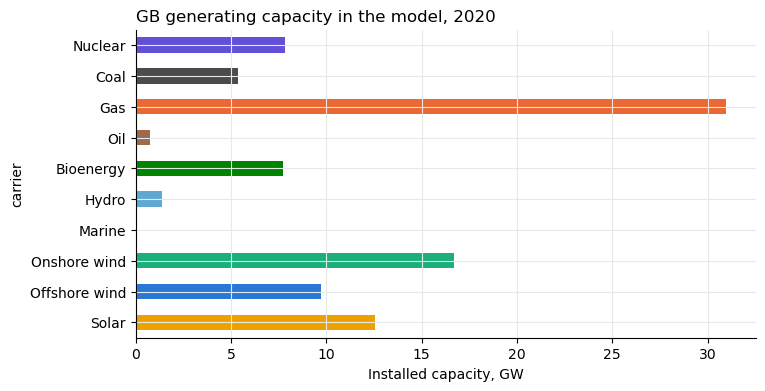

,GW
carrier,
Nuclear,7.8
Coal,5.3
Gas,31.0
Oil,0.8
Bioenergy,7.7
Hydro,1.4
Marine,0.0
Onshore wind,16.7
Offshore wind,9.7


In [3]:
gb_gens = n.generators[n.generators.bus.isin(gb_buses(n)) & n.generators.carrier.isin(GROUP_OF)]
capacity = (gb_gens.p_nom.groupby(gb_gens.carrier.map(GROUP_OF)).sum() / 1e3).reindex(COLOURS).dropna()

ax = capacity.plot.barh(color=[COLOURS[g] for g in capacity.index], figsize=(8, 4))
ax.invert_yaxis()
ax.set_xlabel("Installed capacity, GW")
ax.set_title("GB generating capacity in the model, 2020", loc="left")
plt.show()
capacity.round(1).to_frame("GW")

## How demand was met

The chart stacks each technology's output in each hour, with storage and imports; exports and storage charging are
below zero. The black line is GB demand.

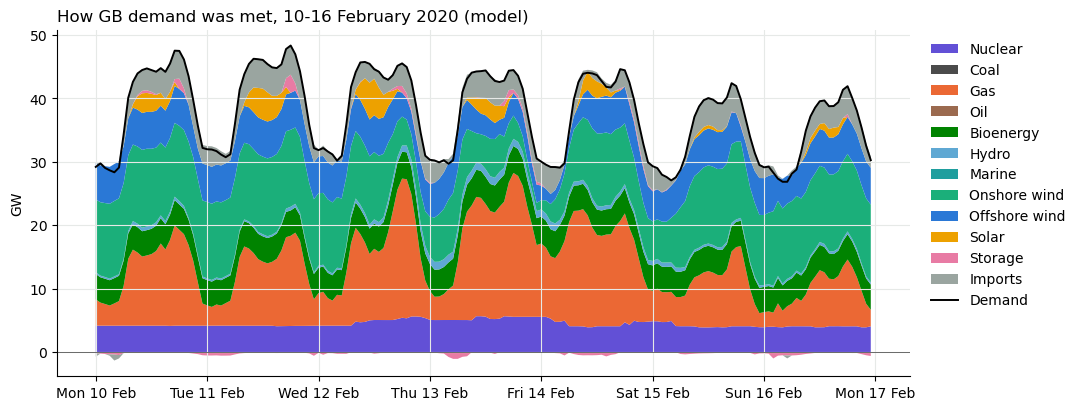

,GWh over the week
carrier,
Nuclear,752.0
Coal,0.0
Gas,1692.0
Oil,0.0
Bioenergy,680.0
Hydro,98.0
Marine,2.0
Onshore wind,1649.0
Offshore wind,856.0


In [4]:
supply = generation_by_group(n)
supply["Storage"] = grid_storage(n)
supply["Imports"] = net_imports(n)
demand = gb_demand(n)

fig, ax = plt.subplots(figsize=(11, 4.5))
stack_plot(ax, supply, demand, title="How GB demand was met, 10-16 February 2020 (model)")
plt.show()

energy = (supply.sum() / 1e3).round(0)   # MWh over the week, in GWh
energy.to_frame("GWh over the week")

Wind carried the week. Onshore and offshore wind met about two-fifths of GB demand, until the wind dropped to
about 4 GW in the early hours of 14 February; gas filled that gap and the evening peaks, before Storm Dennis brought
the wind back on the 15th. Nuclear ran flat all week, and imports filled in, mostly overnight. The model runs no coal at
all: on 2020 fuel and carbon prices coal cost more to run than gas.

## Compare with what happened

ESPENI is a measured record of GB electricity by fuel, every half hour, built from ELEXON and NESO data; the model
already uses it for demand. Here its generation by fuel for the same week sits beside the model's. ESPENI reports wind
as one figure, counts all imports together, and puts waste, landfill gas and other small plant under "other", so the
model's groups are combined to match.

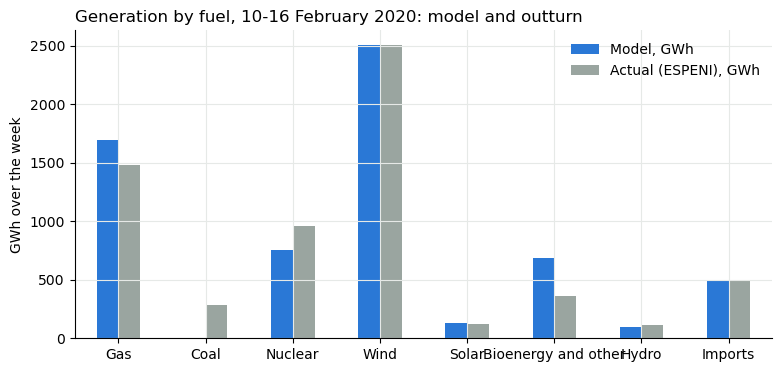

,"Model, GWh","Actual (ESPENI), GWh",Model / actual
Gas,1692.0,1477.0,1.15
Coal,0.0,287.0,0.00
Nuclear,752.0,958.0,0.78
Wind,2505.0,2507.0,1.00
Solar,131.0,118.0,1.11
Bioenergy and other,682.0,358.0,1.91
Hydro,98.0,115.0,0.85
Imports,494.0,497.0,0.99


In [5]:
espeni = pd.read_csv("data/demand/espeni.csv", usecols=lambda c: c.startswith(("ELEC_elex_startTime", "ELEC_POWER")))
espeni.columns = [c.split("[")[0].replace("ELEC_POWER_", "").replace("ELEX_", "") for c in espeni.columns]
espeni["time"] = pd.to_datetime(espeni.pop("ELEC_elex_startTime"), utc=True).dt.tz_localize(None)
week = espeni.set_index("time").loc["2020-02-10":"2020-02-16 23:30"]
hourly = week.resample("h").mean()

actual = pd.Series({
    "Gas": (hourly.CCGT + hourly.OCGT).sum(),
    "Coal": hourly.COAL.sum(),
    "Nuclear": hourly.NUCLEAR.sum(),
    "Wind": hourly.TOTAL_WIND.sum(),
    "Solar": hourly.NGEM_EMBEDDED_SOLAR_GENERATION.sum(),
    "Bioenergy and other": (hourly.BIOMASS_POSTCALC + hourly.OTHER_POSTCALC).sum(),
    "Hydro": hourly.NPSHYD.sum(),
    "Imports": hourly.NET_IMPORTS.sum(),
}) / 1e3

model = energy.rename({"Onshore wind": "Wind", "Offshore wind": "Wind", "Bioenergy": "Bioenergy and other",
                       "Marine": "Bioenergy and other", "Oil": "Bioenergy and other"}).groupby(level=0).sum()
comparison = pd.DataFrame({"Model, GWh": model.reindex(actual.index), "Actual (ESPENI), GWh": actual}).round(0)
comparison["Model / actual"] = (comparison.iloc[:, 0] / comparison.iloc[:, 1]).round(2)

ax = comparison.iloc[:, :2].plot.bar(color=["#2a78d6", "#9aa5a0"], figsize=(9, 4), rot=0)
ax.set_ylabel("GWh over the week")
ax.set_title("Generation by fuel, 10-16 February 2020: model and outturn", loc="left")
plt.show()
comparison

Wind and imports match the real week almost exactly, which says the weather data and the interconnectors are
right. The rest is a simple least-cost dispatch, and it shows:

- **Coal is zero, gas too high.** Coal was dearer than gas in 2020, so a cost-minimising model never runs it; in
  reality a few coal units ran for contracts and system reasons, and gas covered less.
- **"Bioenergy and other" is about twice ESPENI's.** ESPENI records the metered biomass stations but little of
  the small bioenergy embedded in distribution networks (landfill and sewage gas, biogas, small waste plants), which
  the model counts in full; part of the gap is what each counts.
- **Nuclear is low.** The model turns down Scotland's two nuclear stations, Hunterston B and Torness, which sit
  behind the same full lines as Scottish wind (next section). On the larger networks of
  [tutorial 2](2-network-models.ipynb) they run at full output, and nuclear matches the real week.

The [2020 validation study](../studies/validation_2020.md) solves the whole year more carefully (the two-stage
market, each nuclear station at its notified output, generators at their real connection points) and compares it with
ESPENI, ELEXON and NESO month by month.

## Prices and the network

Each bus has its own price: the cost of serving one more MWh there (`n.buses_t.marginal_price`). If the network never
limited a flow, every GB bus would have the same price in a given hour. Where buses differ, a line is full. The first
chart shows the lowest, mean and highest bus price in each hour.

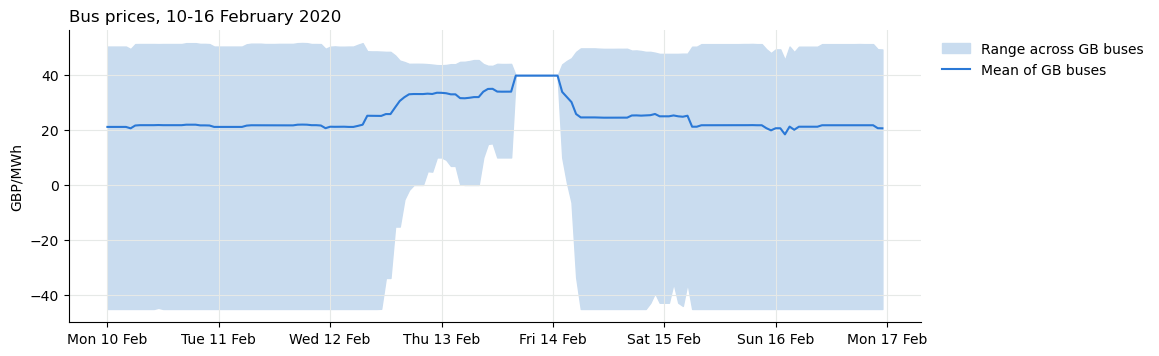

Hours in which GB bus prices differ by more than GBP 1/MWh: 158 of 168


In [6]:
prices = n.buses_t.marginal_price[gb_buses(n)]

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(prices.index, prices.min(axis=1), prices.max(axis=1), color="#c9dcef", label="Range across GB buses")
ax.plot(prices.index, prices.mean(axis=1), color="#2a78d6", lw=1.5, label="Mean of GB buses")
ax.set_ylabel("GBP/MWh")
ax.set_title("Bus prices, 10-16 February 2020", loc="left")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
day_axis(ax)
plt.show()

spread = prices.max(axis=1) - prices.min(axis=1)
print(f"Hours in which GB bus prices differ by more than GBP 1/MWh: {(spread > 1).sum()} of {len(spread)}")

Which lines were full? A line's loading is its flow over its rating. The map colours each line by the share of the
week's hours in which it ran at 99% of its rating or more.

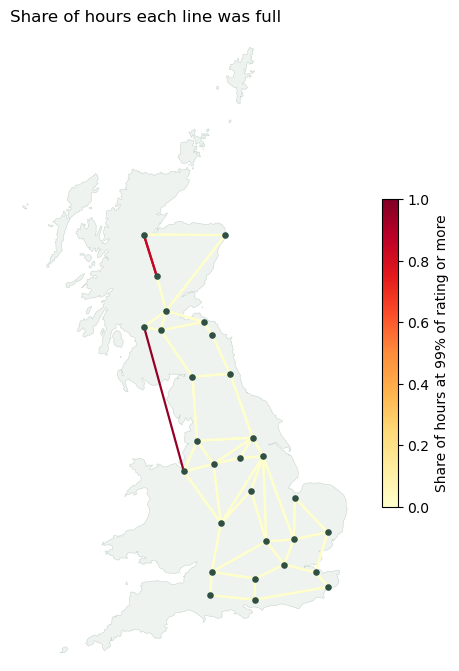

,bus0,bus1,s_nom,share_of_hours_full
name,,,,
16,Neilston,Deeside,2200.0,0.95
1,Beauly,Errochty,132.0,0.85
3,Beauly,Errochty,132.0,0.85
0,Beauly,Peterhead,525.0,0.00
63,Bramford,Kemsley,2780.0,0.00
72,Pelham,Bramford,2780.0,0.00
71,Pelham,Bramford,2780.0,0.00
70,Pelham,London,2780.0,0.00


In [7]:
rating = n.lines.s_nom * n.lines.s_max_pu
loading = n.lines_t.p0.abs() / rating
hours_full = (loading >= 0.99).mean()   # share of hours at the limit

fig, ax = plt.subplots(figsize=(6, 8))
lc = network_map(ax, n, hours_full, cmap="YlOrRd", vmin=0, vmax=1, bus_size=14,
                 title="Share of hours each line was full")
fig.colorbar(lc, ax=ax, shrink=0.5, label="Share of hours at 99% of rating or more")
plt.show()

top = hours_full.sort_values(ascending=False).head(8)
n.lines.loc[top.index, ["bus0", "bus1", "s_nom"]].assign(share_of_hours_full=top.round(2))

Two lines were full nearly all week: the Western HVDC link from Scotland to North Wales, which the Reduced
network represents as the line from Neilston to Deeside (2,200 MW), and the 132 kV circuits from Beauly to Errochty in
the north of Scotland. Behind them, Scottish wind could not reach demand in England. Buses north of the full lines
priced below zero (wind on the Renewables Obligation would rather pay than turn down, because it loses its
certificates), buses south of them priced around GBP 50/MWh, and only during the lull of 13 to 14 February did one
price hold across GB.

## Wind that was not used

Wind farms can run up to their available output (`p_max_pu`, from the weather) but need not. What the model did not
use is curtailed: because supply exceeded what could be used or exported, or because the network could not carry it.

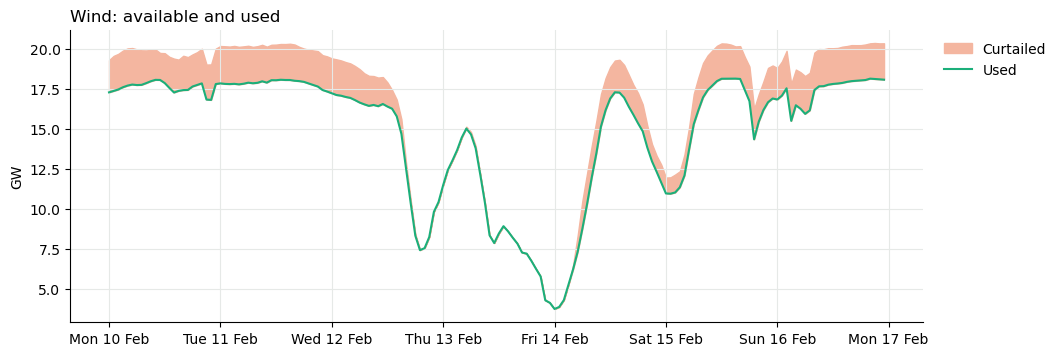

Wind available 2,770 GWh, used 2,505 GWh, curtailed 9.6%


In [8]:
wind = n.generators.index[n.generators.carrier.isin(["wind_onshore", "wind_offshore", "embedded_wind"])
                          & n.generators.bus.isin(gb_buses(n))]
available = (n.generators_t.p_max_pu.reindex(columns=wind, fill_value=1.0) * n.generators.p_nom[wind]).sum(axis=1)
used = n.generators_t.p[wind].sum(axis=1)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(available.index, used / 1e3, available / 1e3, color="#f4b6a0", label="Curtailed")
ax.plot(used.index, used / 1e3, color="#1baf7a", lw=1.5, label="Used")
ax.set_ylabel("GW")
ax.set_title("Wind: available and used", loc="left")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
day_axis(ax)
plt.show()
print(f"Wind available {available.sum() / 1e3:,.0f} GWh, used {used.sum() / 1e3:,.0f} GWh, "
      f"curtailed {(available - used).sum() / available.sum():.1%}")

About a tenth of the available wind was curtailed, nearly all of it in the windy hours, when Scottish wind could not
get past the full lines. In the real system, NESO pays wind farms to turn down in the balancing mechanism in exactly
these hours; [tutorial 5](5-two-stage-market-2030.ipynb) models that step and what it costs.

## Try it yourself

Each change is a new scenario: copy the block below into `config/scenarios.yaml` (or a study of your own), run it
with `snakemake -j 4 --config scenario=<id>`, and point this notebook at the new solved network.

**A calm summer week.** The same network in July, when solar is high and wind low:

```yaml
My_2020_summer_week:
  inherits: Tutorial_2020_reduced
  description: 6-12 July 2020 on the Reduced network
  solve_period: {enabled: true, start: 2020-07-06 00:00, end: 2020-07-12 23:00}
```

**An open-source solver.** The default solver is Gurobi; HiGHS needs no licence and is installed with the environment:

```yaml
My_2020_highs:
  inherits: Tutorial_2020_reduced
  description: the tutorial week solved with HiGHS
  solve:
    solver: {name: highs}
```

**A different year.** Any year from 2010 to 2024 works the same way: set `modelled_year`, `renewables_year` and
`demand_year` together, and a `solve_period` inside that year.

Next: [tutorial 2](2-network-models.ipynb) solves the same week on larger networks.